# Episode 1: What an LLM Really Is
**Companion notebook** for the series *How Large Language Models Work: From Math to Transformers*.

<a href="https://colab.research.google.com/github/Kinvecta/how-llms-work/blob/main/Episode%2001%20-%20What%20an%20LLM%20Really%20Is/notebook.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

Every number you saw in Episode 1 came from this code. It loads **GPT-2 small** (124 million parameters, released by OpenAI in 2019), the small open model from the cold open, and reproduces:

1. the next-token probabilities for *"The cat sat on the"* (floor 7.6%, and "mat" at rank 31)
2. the 11 tokens and the vocabulary size V = 50,257
3. the distribution recomputed as the prefix grows
4. generation as a loop: predict, pick, append, repeat
5. random draws from the same prompt
6. the probability of a whole sentence by the chain rule (about 10⁻¹⁷)

**Run it:** in Colab choose *Runtime → Run all*. It needs `torch` and `transformers` (both preinstalled in Colab) and downloads GPT-2 small once (about 500 MB). A CPU is enough; the whole notebook runs in about a minute.

Values that appear in the episode are checked with `assert`. If a cell fails, a number in the video and the model have drifted apart (for example after a library update), and the printed values show by how much.

In [1]:
# Colab already has these. Elsewhere: pip install torch transformers matplotlib
import math
import torch
import matplotlib.pyplot as plt
from transformers import GPT2LMHeadModel, GPT2TokenizerFast

torch.set_grad_enabled(False)
tokenizer = GPT2TokenizerFast.from_pretrained("gpt2")
model = GPT2LMHeadModel.from_pretrained("gpt2").eval()

def next_token_probs(text):
    """p_theta( . | x_<t ): one probability for every token in the vocabulary."""
    ids = tokenizer(text, return_tensors="pt").input_ids
    logits = model(ids).logits[0, -1]        # scores for the next position
    return torch.softmax(logits, dim=-1)     # turn scores into probabilities (Episode 4)

def show(t):
    return repr(t)                           # repr keeps the leading space visible: ' floor'

## Step 1: what lands on your disk
An LLM is a file of numbers (the parameters, written θ) plus a small program that runs them. GPT-2 small is tiny next to the 70-billion-parameter model from the episode, but it is the same kind of thing.

In [2]:
n_params = sum(p.numel() for p in model.parameters())
print(f"GPT-2 small parameters: {n_params:,}")
print(f"stored as 32-bit floats: {n_params * 4 / 1e6:,.0f} MB")

# The episode's example: Llama 2 70B, stored at 2 bytes per number
llama_params = 70e9
print(f"Llama 2 70B at 2 bytes each: {llama_params * 2 / 1e9:,.0f} GB")

assert 124_000_000 < n_params < 125_000_000
assert round(llama_params * 2 / 1e9) == 140

GPT-2 small parameters: 124,439,808
stored as 32-bit floats: 498 MB
Llama 2 70B at 2 bytes each: 140 GB


## Step 2: tokens and the vocabulary V
The model never sees words. It sees tokens: chunks of text, usually a word or part of one, with the space attached. The set of every token it can output is the vocabulary, **V**.

In [3]:
sentence = "The cat sat on the mat because it was tired."
ids = tokenizer.encode(sentence)
tokens = [tokenizer.decode([i]) for i in ids]

for t, i in zip(tokens, ids):
    print(f"{show(t):12} id {i}")
print("\nnumber of tokens:", len(ids))
print("|V| =", f"{len(tokenizer):,}")

assert len(ids) == 11 and tokens[-1] == "."
assert ids == [464, 3797, 3332, 319, 262, 2603, 780, 340, 373, 10032, 13]
assert len(tokenizer) == 50_257

'The'        id 464
' cat'       id 3797
' sat'       id 3332
' on'        id 319
' the'       id 262
' mat'       id 2603
' because'   id 780
' it'        id 340
' was'       id 373
' tired'     id 10032
'.'          id 13

number of tokens: 11
|V| = 50,257


## Step 3: the cold open, a probability for every token
Give the model *"The cat sat on the"* and ask what comes next. The answer is not a word. It is a list of 50,257 probabilities that add up to 1.

In [4]:
prompt = "The cat sat on the"
p = next_token_probs(prompt)
top = torch.topk(p, 8)

print(f"p( next | {prompt!r} )\n")
for prob, i in zip(top.values, top.indices):
    print(f"  {show(tokenizer.decode(i)):10} {prob.item():6.1%}")

mat_id = tokenizer.encode(" mat")[0]
mat_rank = int((p > p[mat_id]).sum()) + 1
print(f"\n  ' mat' is rank {mat_rank}, probability {p[mat_id].item():.2%}")
print(f"  all {p.numel():,} probabilities sum to {p.sum().item():.4f}")

assert tokenizer.decode(top.indices[0]) == " floor" and round(top.values[0].item(), 3) == 0.076
assert mat_rank == 31 and round(p[mat_id].item(), 4) == 0.0040
assert abs(p.sum().item() - 1) < 1e-4

p( next | 'The cat sat on the' )

  ' floor'     7.6%
  ' bed'       6.5%
  ' couch'     5.4%
  ' ground'    5.2%
  ' edge'      4.8%
  ' bench'     3.2%
  ' table'     3.2%
  ' sofa'      2.9%

  ' mat' is rank 31, probability 0.40%
  all 50,257 probabilities sum to 1.0000


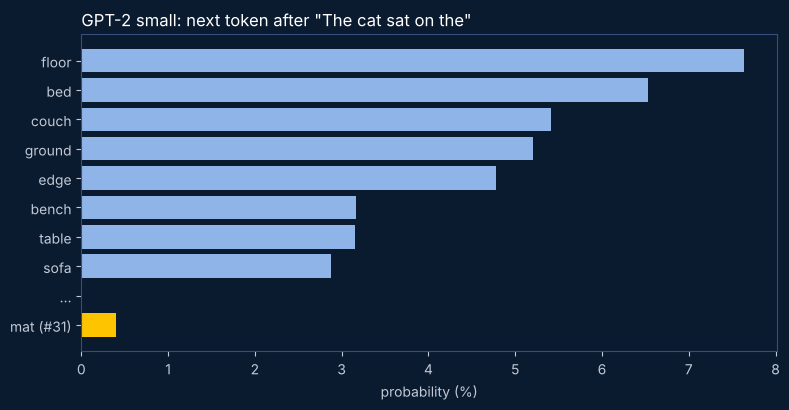

In [5]:
# The same numbers as a chart (Kinvecta colors)
words = [tokenizer.decode(i).strip() for i in top.indices] + ["...", "mat (#31)"]
vals = [v.item() * 100 for v in top.values] + [0, p[mat_id].item() * 100]
colors = ["#8FB4E8"] * 8 + ["#0A1A2F", "#FFC400"]
fig, ax = plt.subplots(figsize=(8, 4.2), facecolor="#0A1A2F")
ax.set_facecolor("#0A1A2F")
ax.barh(words[::-1], vals[::-1], color=colors[::-1])
ax.set_xlabel("probability (%)", color="#C3CAD6")
ax.set_title('GPT-2 small: next token after "The cat sat on the"', color="#FFFFFF", loc="left")
ax.tick_params(colors="#C3CAD6")
for s in ax.spines.values():
    s.set_color("#34507A")
plt.tight_layout()
plt.show()

## Step 4: the one equation, on our sentence
The model computes **p<sub>θ</sub>(x<sub>t</sub> | x<sub>&lt;t</sub>)**: the probability, according to the dials θ, of token *t*, given everything before it (the prefix). Every time the prefix grows by one token, the whole distribution is computed again from scratch.

In [6]:
checks = {                                  # prefix -> (next token in our sentence, probability in the episode)
    "The cat sat": (" on", 0.22),
    "The cat sat on": (" the", 0.45),
    "The cat sat on the mat because": (" it", 0.22),
    "The cat sat on the mat because it": (" was", 0.32),
}
for prefix, (nxt, expected) in checks.items():
    p = next_token_probs(prefix)
    top = torch.topk(p, 3)
    best = ", ".join(f"{show(tokenizer.decode(i))} {v.item():.0%}" for v, i in zip(top.values, top.indices))
    got = p[tokenizer.encode(nxt)[0]].item()
    print(f"{prefix!r:40} top 3: {best}")
    assert tokenizer.decode(top.indices[0]) == nxt and round(got, 2) == expected, (prefix, got)

'The cat sat'                            top 3: ' on' 22%, ' in' 13%, ' down' 7%
'The cat sat on'                         top 3: ' the' 45%, ' a' 11%, ' her' 10%
'The cat sat on the mat because'         top 3: ' it' 22%, ' she' 19%, ' he' 18%
'The cat sat on the mat because it'      top 3: ' was' 32%, ' had' 9%, ' didn' 6%


## Step 5: generation is that equation in a loop
**Predict** the distribution, **pick** a token from it, **append** it to the prefix, **repeat**. Here the pick is the most likely token (greedy), which is why the result is the same every time.

In [7]:
text = "The cat sat on the"
for step in range(9):
    p = next_token_probs(text)               # predict
    i = int(torch.argmax(p))                 # pick (greedy: the top token)
    text += tokenizer.decode([i])            # append
    print(f"step {step + 1}: {text}")        # repeat

assert text == "The cat sat on the floor, and the cat was still asleep."

step 1: The cat sat on the floor
step 2: The cat sat on the floor,
step 3: The cat sat on the floor, and
step 4: The cat sat on the floor, and the


step 5: The cat sat on the floor, and the cat
step 6: The cat sat on the floor, and the cat was
step 7: The cat sat on the floor, and the cat was still


step 8: The cat sat on the floor, and the cat was still asleep
step 9: The cat sat on the floor, and the cat was still asleep.


## Step 6: random picks, different text
Chatbots usually **draw** the next token at random, in proportion to its probability: x<sub>t</sub> ~ p<sub>θ</sub>. Same dials, same prefix, different draws. Change the seed and run it again. (The three continuations in the video were draws like these; your draws will differ.)

In [8]:
def sample(prompt, n_tokens=12, seed=0):
    g = torch.Generator().manual_seed(seed)
    text = prompt
    for _ in range(n_tokens):
        p = next_token_probs(text)
        i = int(torch.multinomial(p, 1, generator=g))   # x_t ~ p_theta( . | x_<t )
        text += tokenizer.decode([i])
    return text

for seed in (1, 2, 3):
    print(f"seed {seed}: {sample('The cat sat on the', seed=seed)!r}")

seed 1: "The cat sat on the steps of Casada's semi-registered car and told him"


seed 2: 'The cat sat on the floor, awaiting down her angry ex-husband. The ex'


seed 3: 'The cat sat on the bright red beam, catapulted about the dog, entw'


## Step 7: a whole sentence, by the chain rule
The probability of a whole sentence is the product of the per-token probabilities:

p(x<sub>1</sub>, …, x<sub>T</sub>) = p(x<sub>1</sub>) · p(x<sub>2</sub> | x<sub>1</sub>) · p(x<sub>3</sub> | x<sub>1</sub>, x<sub>2</sub>) · …

GPT-2 has no prediction for the very first token here, so we score the 10 tokens after "The". Multiplying tiny numbers underflows, so we add logarithms instead (Episode 4 explains why).

In [9]:
ids = torch.tensor([tokenizer.encode(sentence)])
logp = torch.log_softmax(model(ids).logits[0, :-1], dim=-1)            # predictions for positions 2..11
per_token = logp.gather(1, ids[0, 1:, None])[:, 0]                     # log p of each actual next token

for t, lp in zip(tokens[1:], per_token):
    print(f"{show(t):12} p = {math.exp(lp):.4f}")
total = per_token.sum().item()
print(f"\np(sentence | 'The') = exp({total:.2f}) = {math.exp(total):.1e}")

assert 1e-18 < math.exp(total) < 1e-16       # "around ten to the minus seventeen"

' cat'       p = 0.0001
' sat'       p = 0.0007
' on'        p = 0.2240
' the'       p = 0.4537
' mat'       p = 0.0040
' because'   p = 0.0012
' it'        p = 0.2171
' was'       p = 0.3199
' tired'     p = 0.0227
'.'          p = 0.2732

p(sentence | 'The') = exp(-38.76) = 1.5e-17


## Check question
If a model is trained only to predict the next token, why might it still learn to answer questions?

<details><summary>Answer</summary>

Text is full of questions followed by answers. The cheapest way to predict what comes after a question, across millions of them, is to learn the structure that produces good answers. Prediction is the objective; capability is what the objective rewards.

</details>

## Try your own
Change the prompt and run the cell. Watch how sure (or unsure) the model is.

In [10]:
my_prompt = "The capital of Texas is"
p = next_token_probs(my_prompt)
top = torch.topk(p, 5)
for prob, i in zip(top.values, top.indices):
    print(f"{show(tokenizer.decode(i)):12} {prob.item():6.1%}")

# A small 2019 model is not a fact engine: where does the right answer land?
austin = tokenizer.encode(" Austin")[0]
print(f"\n' Austin' is rank {int((p > p[austin]).sum()) + 1}, probability {p[austin].item():.2%}")

' home'        9.9%
' the'         7.7%
' a'           6.8%
' in'          3.1%
' now'         2.5%

' Austin' is rank 23, probability 0.54%


In [11]:
print("All Episode 1 checks passed.")

All Episode 1 checks passed.
